# 사람 영상에서 로봇 학습까지: 실제 R3M으로 확인하기
**최지안**

영상에서 상호작용을 보고, 실제 사전학습 R3M으로 비슷한 장면을 찾고, 그 결과만으로 로봇이 움직일 수 없는 이유를 확인합니다.
데이터 주석과 VRB 실행 구간은 제외했습니다. VRB는 PPT에서 설명합니다.

이 노트북은 R3M 인코더의 **실제 추론**을 수행합니다. 모델 훈련·로봇 정책 훈련·논문 성공률 재현은 수행하지 않습니다.

## A · 사람 영상에 담긴 상호작용
**A1 하나만 실행합니다.** 세 영상을 짧게 재생하고 아래 `cmu_1`의 세 프레임을 봅니다.
각 시각은 설명용으로 고른 값입니다. 공식 상태 변화 라벨이나 데이터 주석이 아닙니다.
영상 3개는 Ego4D 홈페이지 공개 샘플이며 파일명은 원본 video_uid가 아닙니다.

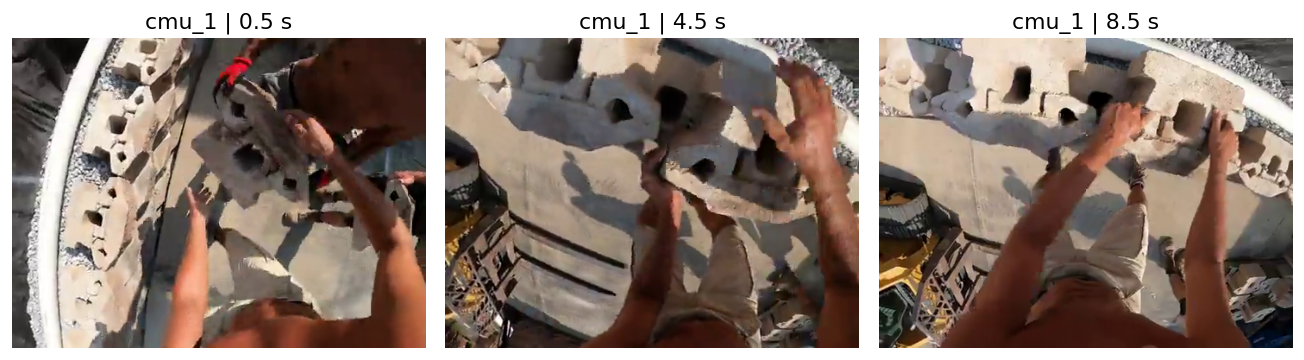

**보이는 것:** 손·물체·시간에 따른 변화. **아직 없는 것:** 로봇 관절 명령·힘·깊이.

**PPT 5쪽으로 돌아갑니다.**

A1 완료: 1.7초. R3M 가중치는 백그라운드 준비 중입니다.


In [44]:
# A1 | PPT 4쪽 뒤 · 준비와 영상 보기를 한 번에 실행합니다 (3분).
# 데이터 주석(annotation)은 사용하지 않습니다. 아래 # 문장은 코드 설명입니다.
import sys, os, time, json, math, hashlib, base64, io, subprocess, importlib.util
from pathlib import Path
from urllib.request import Request, urlopen
from concurrent.futures import ThreadPoolExecutor

started = time.perf_counter()
packages = {'numpy':'numpy', 'matplotlib':'matplotlib', 'cv2':'opencv-python-headless',
            'PIL':'Pillow', 'gdown':'gdown', 'torch':'torch', 'torchvision':'torchvision'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import numpy as np
import matplotlib.pyplot as plt
import cv2, gdown
from PIL import Image
from IPython.display import display, HTML, Markdown

BASE = Path.cwd() / 'ego4d_r3m_lab'
DATA = BASE / 'data'; MODELS = BASE / 'models'; RESULTS = BASE / 'results'
for folder in (DATA, MODELS, RESULTS): folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False})
NAVY, TEAL, ORANGE = '#182B43', '#008577', '#DE7D26'

# 공식 홈페이지의 작은 공개 MP4입니다. 전체 Ego4D 데이터셋 다운로드가 아닙니다.
VIDEO_MANIFEST = [
    ('bristol_1','https://assets.ego4d-data.org/videos/bristol/1.mp4','f8a591555d2e10bb131c6b45682ab5a8f3c7c391556749d940feed759f6bc07d'),
    ('cmu_1','https://assets.ego4d-data.org/videos/cmu/1.mp4','80990a403bb4e8b196df2eb843db64daeee7416d22000da299518a38b8007034'),
    ('iiith_1','https://assets.ego4d-data.org/videos/iiith/1.mp4','9b6a7416abadf128e7f2d7716df779ff57d8b37651e4f9a0221da58d97246a9a')]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()

def fetch_video(name, url, sha):
    path = DATA / (name+'.mp4')
    if not path.exists():
        with urlopen(Request(url, headers={'User-Agent':'Ego4D-seminar'}),timeout=45) as r:
            raw = r.read()
        if hashlib.sha256(raw).hexdigest() != sha:
            raise ValueError('공식 영상 파일이 기준 파일과 다릅니다: '+name)
        path.write_bytes(raw)
    if sha256_file(path) != sha: raise ValueError('캐시 영상의 해시 불일치: '+name)
    return path

# PPT를 설명하는 동안 B에서 쓸 실제 R3M 가중치(약 330 MB)를 백그라운드로 받습니다.
# A의 영상 출력은 모델 다운로드 완료를 기다리지 않습니다.
R3M_ID = '1A1ic-p4KtYlKXdXHcV2QV0cUzI4kn0u-'
R3M_SHA = 'b4dd6f407416889b864c70af974f416daacae0dd360334b5045861120ae336d2'
def prepare_r3m_weights():
    path = MODELS/'r3m18.pt'
    if path.exists() and sha256_file(path)==R3M_SHA: return path
    temp = MODELS/'r3m18.download'
    # 공개 가중치만 사용합니다. Google 로그인·개인 Drive 접근은 필요하지 않습니다.
    result = gdown.download(id=R3M_ID, output=str(temp), quiet=True, use_cookies=False)
    if not result or sha256_file(temp)!=R3M_SHA:
        raise RuntimeError('R3M 공식 가중치 다운로드 또는 무결성 확인 실패. A1을 다시 실행하세요.')
    temp.replace(path)
    return path

# A를 다시 실행해도 진행 중인 다운로드를 중복 시작하지 않습니다.
if 'weight_future' not in globals() or (weight_future.done() and weight_future.exception()):
    weight_pool = ThreadPoolExecutor(max_workers=1)
    weight_future = weight_pool.submit(prepare_r3m_weights)

video_paths = {n:fetch_video(n,u,h) for n,u,h in VIDEO_MANIFEST}
def read_frame(name, seconds):
    """고정 FPS 공개 샘플에서 시각에 해당하는 프레임을 RGB로 반환합니다."""
    cap = cv2.VideoCapture(str(video_paths[name]))
    try:
        fps = cap.get(cv2.CAP_PROP_FPS); count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        if fps<=0 or count<=0: raise RuntimeError('영상 디코딩 실패: '+name)
        if not 0<=seconds<count/fps: raise ValueError('영상 범위 밖의 시각')
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(seconds*fps))
        ok, frame = cap.read()
        if not ok: raise RuntimeError('프레임 읽기 실패')
        return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    finally: cap.release()

# IPython Video의 버전별 경로 오류를 피하고, 작은 영상을 HTML에 직접 넣습니다.
players=[]
for name,url,_ in VIDEO_MANIFEST:
    payload=base64.b64encode(video_paths[name].read_bytes()).decode('ascii')
    players.append(f'<div style="flex:1;min-width:230px"><b>{name}</b><br>'
                   f'<video controls muted playsinline preload="metadata" style="width:100%" '
                   f'src="data:video/mp4;base64,{payload}"></video></div>')
display(HTML('<div style="display:flex;gap:16px;flex-wrap:wrap">'+''.join(players)+'</div>'))

# 대표 영상은 계속 재사용합니다. 시각은 설명용이며 공식 PRE/PNR/POST 라벨이 아닙니다.
SAMPLE='cmu_1'
fig,axs=plt.subplots(1,3,figsize=(11,3))
for ax,t in zip(axs,[0.5,4.5,8.5]):
    ax.imshow(read_frame(SAMPLE,t));ax.set_title(f'{SAMPLE} | {t:.1f} s');ax.axis('off')
fig.tight_layout();fig.savefig(RESULTS/'A_frames.png',bbox_inches='tight');plt.show();plt.close(fig)
display(Markdown('**보이는 것:** 손·물체·시간에 따른 변화. **아직 없는 것:** 로봇 관절 명령·힘·깊이.\n\n**PPT 5쪽으로 돌아갑니다.**'))
print(f'A1 완료: {time.perf_counter()-started:.1f}초. R3M 가중치는 백그라운드 준비 중입니다.')


## B · 실제 R3M 특징은 무엇을 해 주는가
**B1 하나만 실행합니다.** `cmu_1` 4.5초 프레임을 기준으로, 3개 영상에서 추출한 프레임 중 특징이 가까운 장면을 찾습니다.

계산 흐름: **RGB 프레임 → 공식 전처리 → 고정 R3M 인코더 → 512차원 특징 → L2 거리 → 프레임 검색**.

$$z_i=F_\phi(I_i),\qquad d_i=\|z_i-z_q\|_2.$$

작은 거리는 이 특징 공간에서 가깝다는 뜻입니다. 시각적으로 무엇이 비슷한지 결과 프레임으로 확인합니다. 같은 영상의 바로 인접한 프레임은 검색 후보에서 제외합니다. 아래 그래프는 특징 거리가 작업 진행도나 성공 확률과 같지 않다는 점도 보여줍니다.

공식 R3M ResNet18 가중치에서 시각 인코더만 읽습니다. 언어 모듈과 학습용 optimizer는 필요하지 않습니다. 공개 원본의 키와 구조를 확인하며 `strict=True`로 로드합니다. 가중치 SHA256도 확인합니다.

실행 장치: cpu | 가중치 준비를 확인합니다…


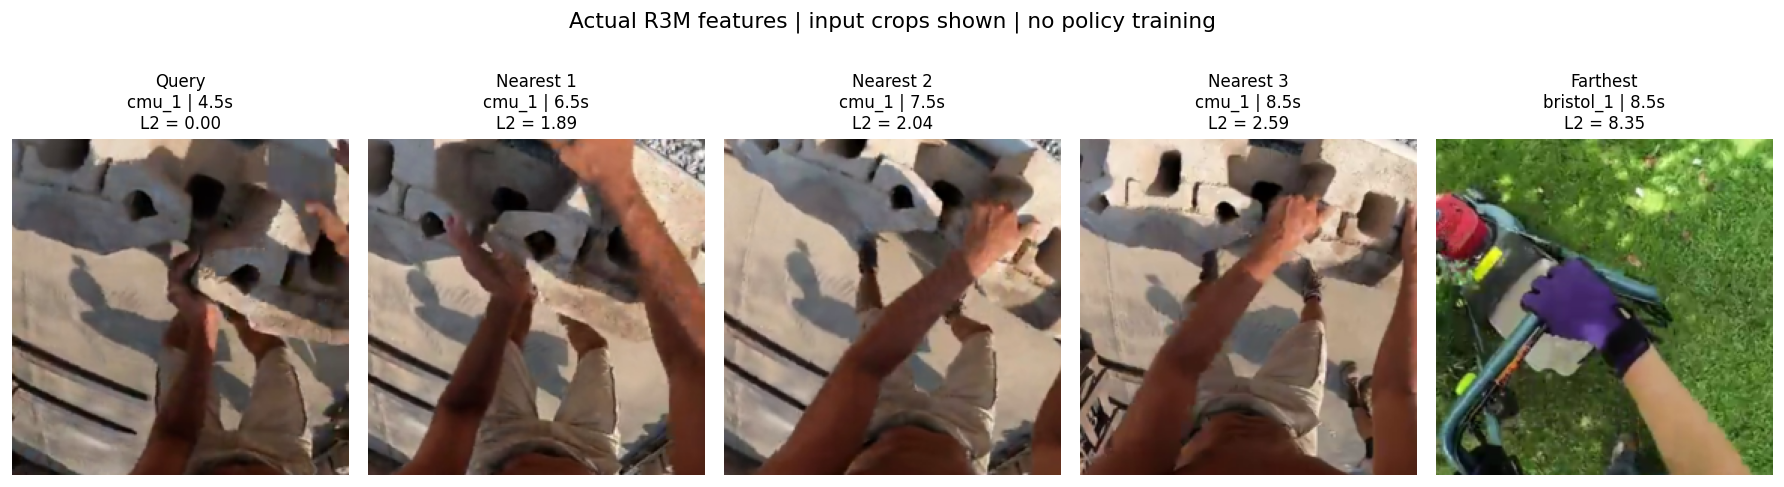

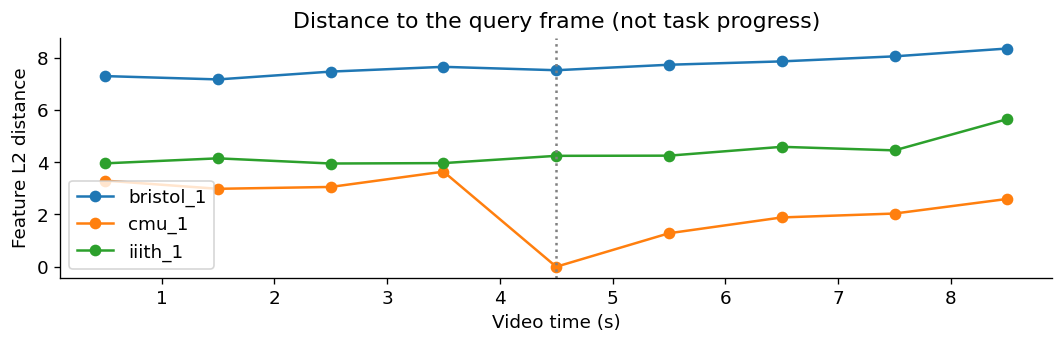

**27장의 이미지 → 각각 512차원 특징 → 가까운 장면 검색.**

장면이 비슷하다고 판단하는 데 쓰였지만, 로봇이 어떻게 움직일지는 출력하지 않았습니다. 이 작은 예제는 R3M의 일반화 성능이나 로봇 성공률 평가가 아닙니다.

**PPT 15쪽으로 돌아갑니다.**

B1 완료: 12.4초 | torch 2.11.0+cpu


In [ ]:
# B1 | PPT 14쪽 뒤 · 실제 R3M 특징으로 가까운 장면을 찾습니다.
# 학습을 새로 하는 것이 아니라, 사람 영상으로 사전학습된 인코더를 실행합니다.
if 'video_paths' not in globals(): raise RuntimeError('A1을 먼저 실행하세요.')
started=time.perf_counter()
import torch, torchvision
from torchvision import transforms
torch.set_num_threads(min(4,os.cpu_count() or 1))
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('실행 장치:',device,'| 가중치 준비를 확인합니다…')
weight_path=weight_future.result(timeout=240)

# 공식 R3M의 resnet18 시각 인코더만 로드합니다.
# 원본 체크포인트의 언어 모듈은 이 이미지 특징 추론에서 사용하지 않습니다.
# strict=True는 모든 인코더 가중치의 이름과 모양이 맞는지 검사합니다.
checkpoint=torch.load(weight_path,map_location='cpu',weights_only=True)
state={k.removeprefix('module.convnet.'):v for k,v in checkpoint['r3m'].items()
       if k.startswith('module.convnet.')}
encoder=torchvision.models.resnet18(weights=None)
encoder.fc=torch.nn.Identity()
encoder.load_state_dict(state,strict=True)
encoder=encoder.to(device).eval()
del checkpoint,state

# 공식 사용 예제와 동일하게 짧은 변 256 → 중앙 224 crop → ImageNet 채널 정규화.
# ToTensor가 [0,255]를 [0,1]로 바꾸므로 다시 255로 나누지 않습니다.
crop=transforms.Compose([transforms.Resize(256),transforms.CenterCrop(224)])
preprocess=transforms.Compose([crop,transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

items=[]
for name in video_paths:
    for t in np.arange(0.5,9.0,1.0):
        im=Image.fromarray(read_frame(name,float(t)))
        items.append({'name':name,'time':float(t),'image':im})
batch=torch.stack([preprocess(r['image']) for r in items]).to(device)
with torch.inference_mode():
    # 작은 배치로 나누어 GPU가 없는 환경에서도 메모리 사용을 줄입니다.
    features=torch.cat([encoder(x) for x in batch.split(8)]).cpu()
assert features.shape==(27,512) and torch.isfinite(features).all()
query=next(i for i,r in enumerate(items) if r['name']==SAMPLE and r['time']==4.5)
query_image=items[query]['image']

# R3M 논문의 시간 대조 학습에서 사용하는 거리와 연결되는 L2 거리입니다.
# 작은 거리 = 이 특징 공간에서 가까움. 작업 성공 확률이나 행동 라벨이 아닙니다.
distance=torch.linalg.vector_norm(features-features[query],dim=1).numpy()
# 자기 자신과 바로 옆 시점을 빼서 '거의 똑같은 프레임 찾기'만 되지 않도록 합니다.
eligible=np.array([not(r['name']==SAMPLE and abs(r['time']-4.5)<=1.01) for r in items])
ranking=np.flatnonzero(eligible)[np.argsort(distance[eligible])]
selected=[query,*ranking[:3],ranking[-1]]
fig,axs=plt.subplots(1,5,figsize=(15,4.2))
for ax,index,label in zip(axs,selected,['Query','Nearest 1','Nearest 2','Nearest 3','Farthest']):
    r=items[index];ax.imshow(crop(r['image']));ax.axis('off')
    ax.set_title(f"{label}\n{r['name']} | {r['time']:.1f}s\nL2 = {distance[index]:.2f}",fontsize=10)
fig.suptitle('Actual R3M features | input crops shown | no policy training',fontsize=13)
fig.tight_layout(rect=[0,0,1,0.87]);fig.savefig(RESULTS/'B_retrieval.png',bbox_inches='tight');plt.show();plt.close(fig)

# 시간축 전체를 같이 보아, 특징 거리를 '진행도'로 단정하지 않도록 합니다.
fig,ax=plt.subplots(figsize=(9,3))
for name in video_paths:
    idx=[i for i,r in enumerate(items) if r['name']==name]
    ax.plot([items[i]['time'] for i in idx],distance[idx],'-o',label=name)
ax.axvline(4.5,color='gray',ls=':');ax.set(xlabel='Video time (s)',ylabel='Feature L2 distance',
    title='Distance to the query frame (not task progress)');ax.legend()
fig.tight_layout();fig.savefig(RESULTS/'B_distance.png',bbox_inches='tight');plt.show();plt.close(fig)

np.savez(RESULTS/'r3m_features.npz',features=features.numpy(),distance=distance,
         names=np.array([r['name'] for r in items]),times=np.array([r['time'] for r in items]))
display(Markdown(f'**27장의 이미지 → 각각 512차원 특징 → 가까운 장면 검색.**\n\n'
    '장면이 비슷하다고 판단하는 데 쓰였지만, 로봇이 어떻게 움직일지는 출력하지 않았습니다. '
    '이 작은 예제는 R3M의 일반화 성능이나 로봇 성공률 평가가 아닙니다.\n\n**PPT 15쪽으로 돌아갑니다.**'))
print(f'B1 완료: {time.perf_counter()-started:.1f}초 | torch {torch.__version__}')


## 출처와 실행 범위
- [Ego4D](https://ego4d-data.org/) · [공개 지도 영상 연결](https://ego4d-data.org/assets/scripts/map-tooltip.js): A의 공개 샘플 3개.
- [R3M 공식 코드](https://github.com/facebookresearch/r3m/tree/b2334e726887fa0206962d7984c69c5fb09cceab) · [인코더 전처리](https://github.com/facebookresearch/r3m/blob/b2334e726887fa0206962d7984c69c5fb09cceab/r3m/models/models_r3m.py): B의 모델·입력 처리·가중치 출처.
- [R3M 논문](https://proceedings.mlr.press/v205/nair23a.html): 시간·언어 손실과 표현 학습, 후속 로봇 정책 학습.
- [OpenCV 카메라 모델](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html): C의 핀홀 투영식.

영상과 모델 파일은 각 공식 출처에서 받습니다. 원본 가중치의 다운로드 실패를 임의 특징이나 사전 계산 결과로 숨기지 않습니다. 결과 파일은 런타임의 `ego4d_r3m_lab/results`에 저장됩니다. `B_retrieval.png`, `B_distance.png`, `C_depth.png`와 계산 배열을 다시 사용할 수 있습니다.